c:\Users\Pc\Documents\tess-transit-project\.venv\Lib\site-packages\lightkurve\prf\__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


SearchResult containing 11 data products.

 #     mission     year author exptime target_name distance
                                  s                 arcsec 
--- -------------- ---- ------ ------- ----------- --------
  0 TESS Sector 09 2019   SPOC     120    35516889      0.0
  1 TESS Sector 36 2021   SPOC      20    35516889      0.0
  2 TESS Sector 36 2021   SPOC     120    35516889      0.0
  3 TESS Sector 62 2023   SPOC     120    35516889      0.0
  4 TESS Sector 63 2023   SPOC     120    35516889      0.0
  5 TESS Sector 89 2025   SPOC      20    35516889      0.0
  6 TESS Sector 90 2025   SPOC      20    35516889      0.0
  7 TESS Sector 89 2025   SPOC     120    35516889      0.0
  8 TESS Sector 90 2025   SPOC     120    35516889      0.0
  9 TESS Sector 99 2026   SPOC      20    35516889      0.0
 10 TESS Sector 99 2026   SPOC     120    35516889      0.0


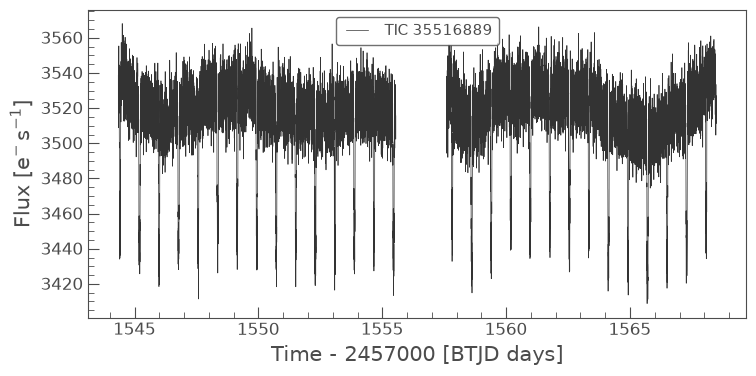

In [1]:
import lightkurve as lk
import numpy as np
import matplotlib.pyplot as plt

search = lk.search_lightcurve("WASP-19", mission="TESS", author="SPOC")
print(search)

lc_1 = search[0].download()
lc_1.plot()
plt.show()

In [2]:
import lightkurve as lk
import numpy as np
import matplotlib.pyplot as plt

search = lk.search_lightcurve("WASP-19", mission="TESS", author="SPOC")
print(search)

lc_2 = search[2].download()
plt.show()

SearchResult containing 11 data products.

 #     mission     year author exptime target_name distance
                                  s                 arcsec 
--- -------------- ---- ------ ------- ----------- --------
  0 TESS Sector 09 2019   SPOC     120    35516889      0.0
  1 TESS Sector 36 2021   SPOC      20    35516889      0.0
  2 TESS Sector 36 2021   SPOC     120    35516889      0.0
  3 TESS Sector 62 2023   SPOC     120    35516889      0.0
  4 TESS Sector 63 2023   SPOC     120    35516889      0.0
  5 TESS Sector 89 2025   SPOC      20    35516889      0.0
  6 TESS Sector 90 2025   SPOC      20    35516889      0.0
  7 TESS Sector 89 2025   SPOC     120    35516889      0.0
  8 TESS Sector 90 2025   SPOC     120    35516889      0.0
  9 TESS Sector 99 2026   SPOC      20    35516889      0.0
 10 TESS Sector 99 2026   SPOC     120    35516889      0.0


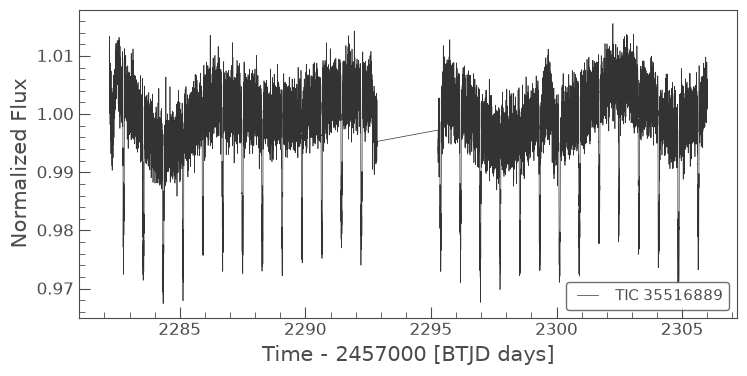

In [3]:
import matplotlib.pyplot as plt

lc_2_clean = lc_2.remove_nans().normalize()

lc_2_clean.plot()
plt.show()

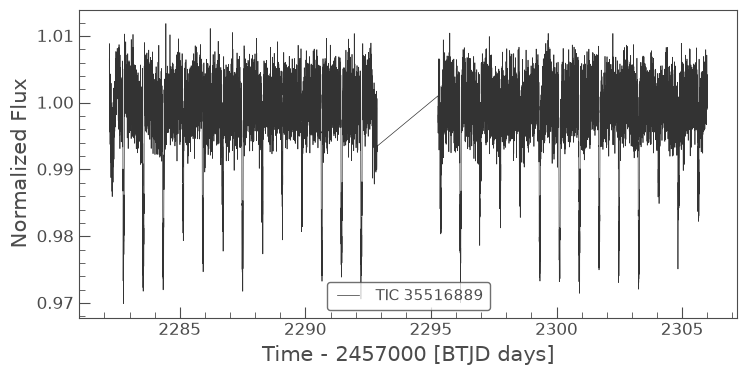

In [4]:
import matplotlib.pyplot as plt

lc_2_flat = lc_2_clean.flatten(window_length=901)
lc_2_flat.plot()
plt.show()

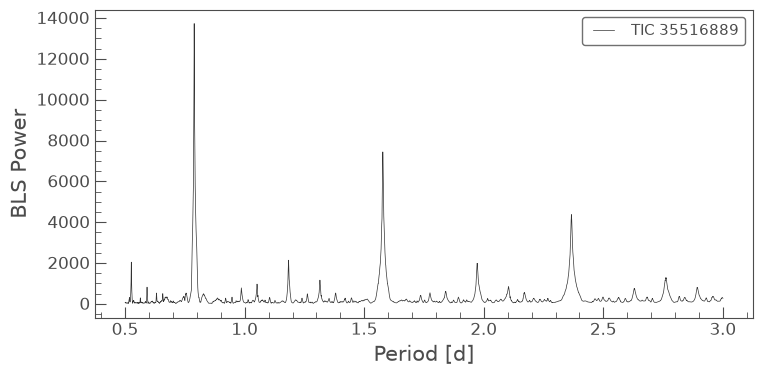

In [5]:
import numpy as np

periods = np.linspace(0.5, 3, 10000)
bls = lc_2_flat.to_periodogram(method="bls", period=periods)

bls.plot()
plt.show()

In [6]:
import numpy as np

period = bls.period_at_max_power
t0 = bls.transit_time_at_max_power
duration = bls.duration_at_max_power

print("Period =", period)
print("t0 =", t0)
print("duration =", duration)



Period = 0.7887788778877888 d
t0 = 2282.7645816874306
duration = 0.05 d


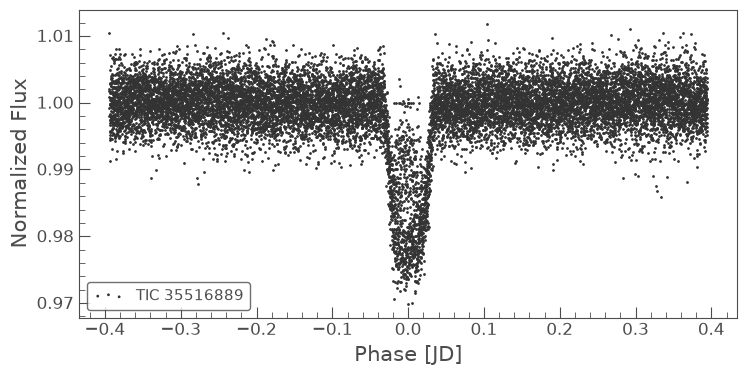

In [7]:
import matplotlib.pyplot as plt

lc_2_flat.fold(period=period, epoch_time=t0).scatter()
plt.show()

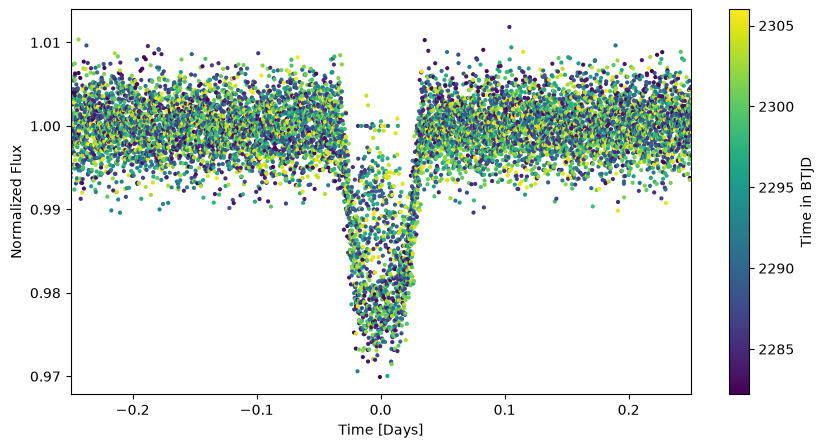

In [8]:
import matplotlib.pyplot as plt

folded = lc_2_flat.fold(period=period, epoch_time=t0)
plt.figure(figsize=(10, 5))
sc = plt.scatter(folded.time.value, folded.flux.value, c=folded.time_original.value, s=4, cmap="viridis")

plt.colorbar(sc, label="Time in BTJD")
plt.xlim(-0.25, 0.25)
plt.xlabel("Time [Days]")
plt.ylabel("Normalized Flux")
plt.show()

Number of masked data points 3883 from 15347


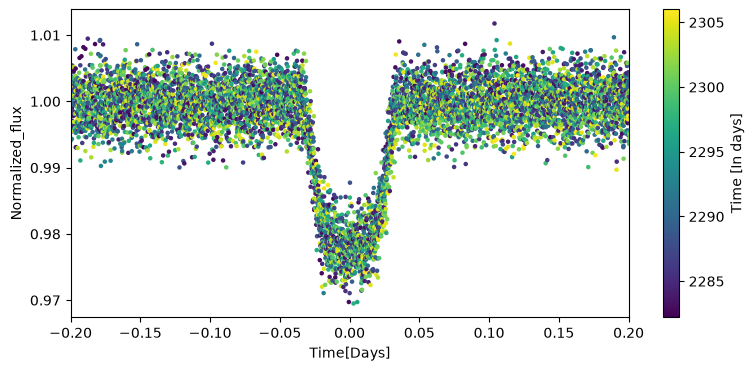

In [19]:
import numpy as np
import matplotlib.pyplot as plt

t = lc_2_clean.time.value
t = np.asarray(getattr(t, "unmasked", t), dtype=float)
P = float(period.value)
T0 = float(t0.value)
dur = 0.20

transit_mask = np.abs((t - T0 + P/2) % P - P/2) < dur/2
print("Number of masked data points", transit_mask.sum(), "from", len(t))

lc_2_flat2 = lc_2_clean.flatten(window_length = 901, mask = transit_mask)

folded2 = lc_2_flat2.fold(period = period, epoch_time = t0)
plt.figure(figsize=(9, 4))
sc = plt.scatter(folded2.time.value, folded2.flux.value, c=folded2.time_original.value, s=5, cmap="viridis")
plt.colorbar(sc, label="Time [In days]")
plt.xlim(-0.2, 0.2)
plt.xlabel("Time[Days]")
plt.ylabel("Normalized_flux")
plt.show()
